# WebAssembly Interaction with JavaScript

WebAssembly (Wasm) is a binary instruction format that enables near-native performance in web browsers and beyond. This course covers how JavaScript interacts with WebAssembly modules — from loading and instantiation through memory, functions, globals, exception handling, and the broader ecosystem of runtimes and toolchains.

## Table of Contents

1. [Module 01: Introduction to WebAssembly](#module-01-introduction-to-webassembly)
2. [Module 02: Loading Modules with the WebAssembly JavaScript API](#module-02-loading-modules-with-the-webassembly-javascript-api)
3. [Module 03: Functions](#module-03-functions)
4. [Module 04: Globals and Memory](#module-04-globals-and-memory)
5. [Module 05: Exception Handling and Debugging](#module-05-exception-handling-and-debugging)
6. [Module 06: Runtimes](#module-06-runtimes)
7. [Module 07: Tools and Languages](#module-07-tools-and-languages)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Introduction to WebAssembly

WebAssembly is a binary instruction format for a stack-based virtual machine that executes at near-native speed. It is designed as a compilation target for languages like C, C++, Rust, and others, enabling high-performance code to run in the browser alongside JavaScript.

### What is WebAssembly?

WebAssembly (Wasm) is:

- A **binary instruction format** for a stack-based virtual machine
- Designed as a **portable compilation target** for programming languages
- Enables deployment on the web for **client and server applications**
- Runs at **near-native speed** by leveraging common hardware capabilities

> WebAssembly is an open standard developed by the W3C WebAssembly Community Group.

WebAssembly is designed to complement JavaScript — not replace it. The two technologies work together: JavaScript handles high-level application logic and DOM interaction, while WebAssembly handles computationally intensive tasks.

### WebAssembly Goals

The design goals of WebAssembly are:

- **Fast** — executes at near-native speed through compact binary format and ahead-of-time compilation
- **Safe** — runs in a sandboxed environment with enforced memory-safe execution
- **Open** — an open W3C standard, human-readable text format available, no vendor lock-in
- **Portable** — hardware, language, and platform independent; runs in any modern browser or runtime
- **Compact** — binary format is smaller than equivalent JavaScript and faster to transmit and parse
- **Debuggable** — the WAT (WebAssembly Text Format) makes Wasm code readable and inspectable

### WebAssembly Text Format (WAT)

WebAssembly has two representations:

- **Binary format** (`.wasm`) — compact bytecode executed by the runtime
- **Text format** (`.wat`) — human-readable S-expression syntax for authoring and debugging

WAT uses an S-expression syntax (parenthesised lists). Every `.wat` file can be compiled to `.wasm` using the `wat2wasm` tool, and `.wasm` can be decompiled back to `.wat` with `wasm2wat`.

```wat
(module
  (func $add (param $a i32) (param $b i32) (result i32)
    local.get $a
    local.get $b
    i32.add
  )
  (export "add" (func $add))
)
```

This module exports a single function `add` that takes two 32-bit integers and returns their sum.

### Module vs. Instance

| Concept | Description |
|---|---|
| **WebAssembly Module** | The compiled binary code — a `WebAssembly.Module` object. Stateless; can be stored, transferred, and instantiated multiple times. |
| **WebAssembly Instance** | A running instance of a module — a `WebAssembly.Instance` object. Has its own memory, table, and global state. |

A module is like a class definition; an instance is like an object created from that class. Multiple instances can be created from the same module, each with independent state.

### WebAssembly Value Types

WebAssembly has four core numeric types:

| Type | Description |
|---|---|
| `i32` | 32-bit integer |
| `i64` | 64-bit integer |
| `f32` | 32-bit floating point |
| `f64` | 64-bit floating point |

There are no boolean, string, or complex types at the WebAssembly boundary. Strings and complex data structures must be passed through linear memory and decoded in JavaScript using APIs like `TextDecoder`.

The newer **reference types** proposal adds:
- `funcref` — reference to a function
- `externref` — reference to an external (JavaScript) object

### A Typical WebAssembly Application Architecture

In a typical web application using WebAssembly:

1. **Source code** (C/C++, Rust, etc.) is compiled to a `.wasm` binary
2. **JavaScript** fetches and instantiates the `.wasm` module using the WebAssembly JavaScript API
3. **Exports** from the Wasm module (functions, memory, globals) are accessed via the instance's `exports` object
4. **Imports** allow the Wasm module to call back into JavaScript (e.g., `console.log`, DOM APIs)
5. **Shared memory** (`WebAssembly.Memory`) enables efficient data transfer between JS and Wasm

The JavaScript WebAssembly API is the bridge between the two execution environments.


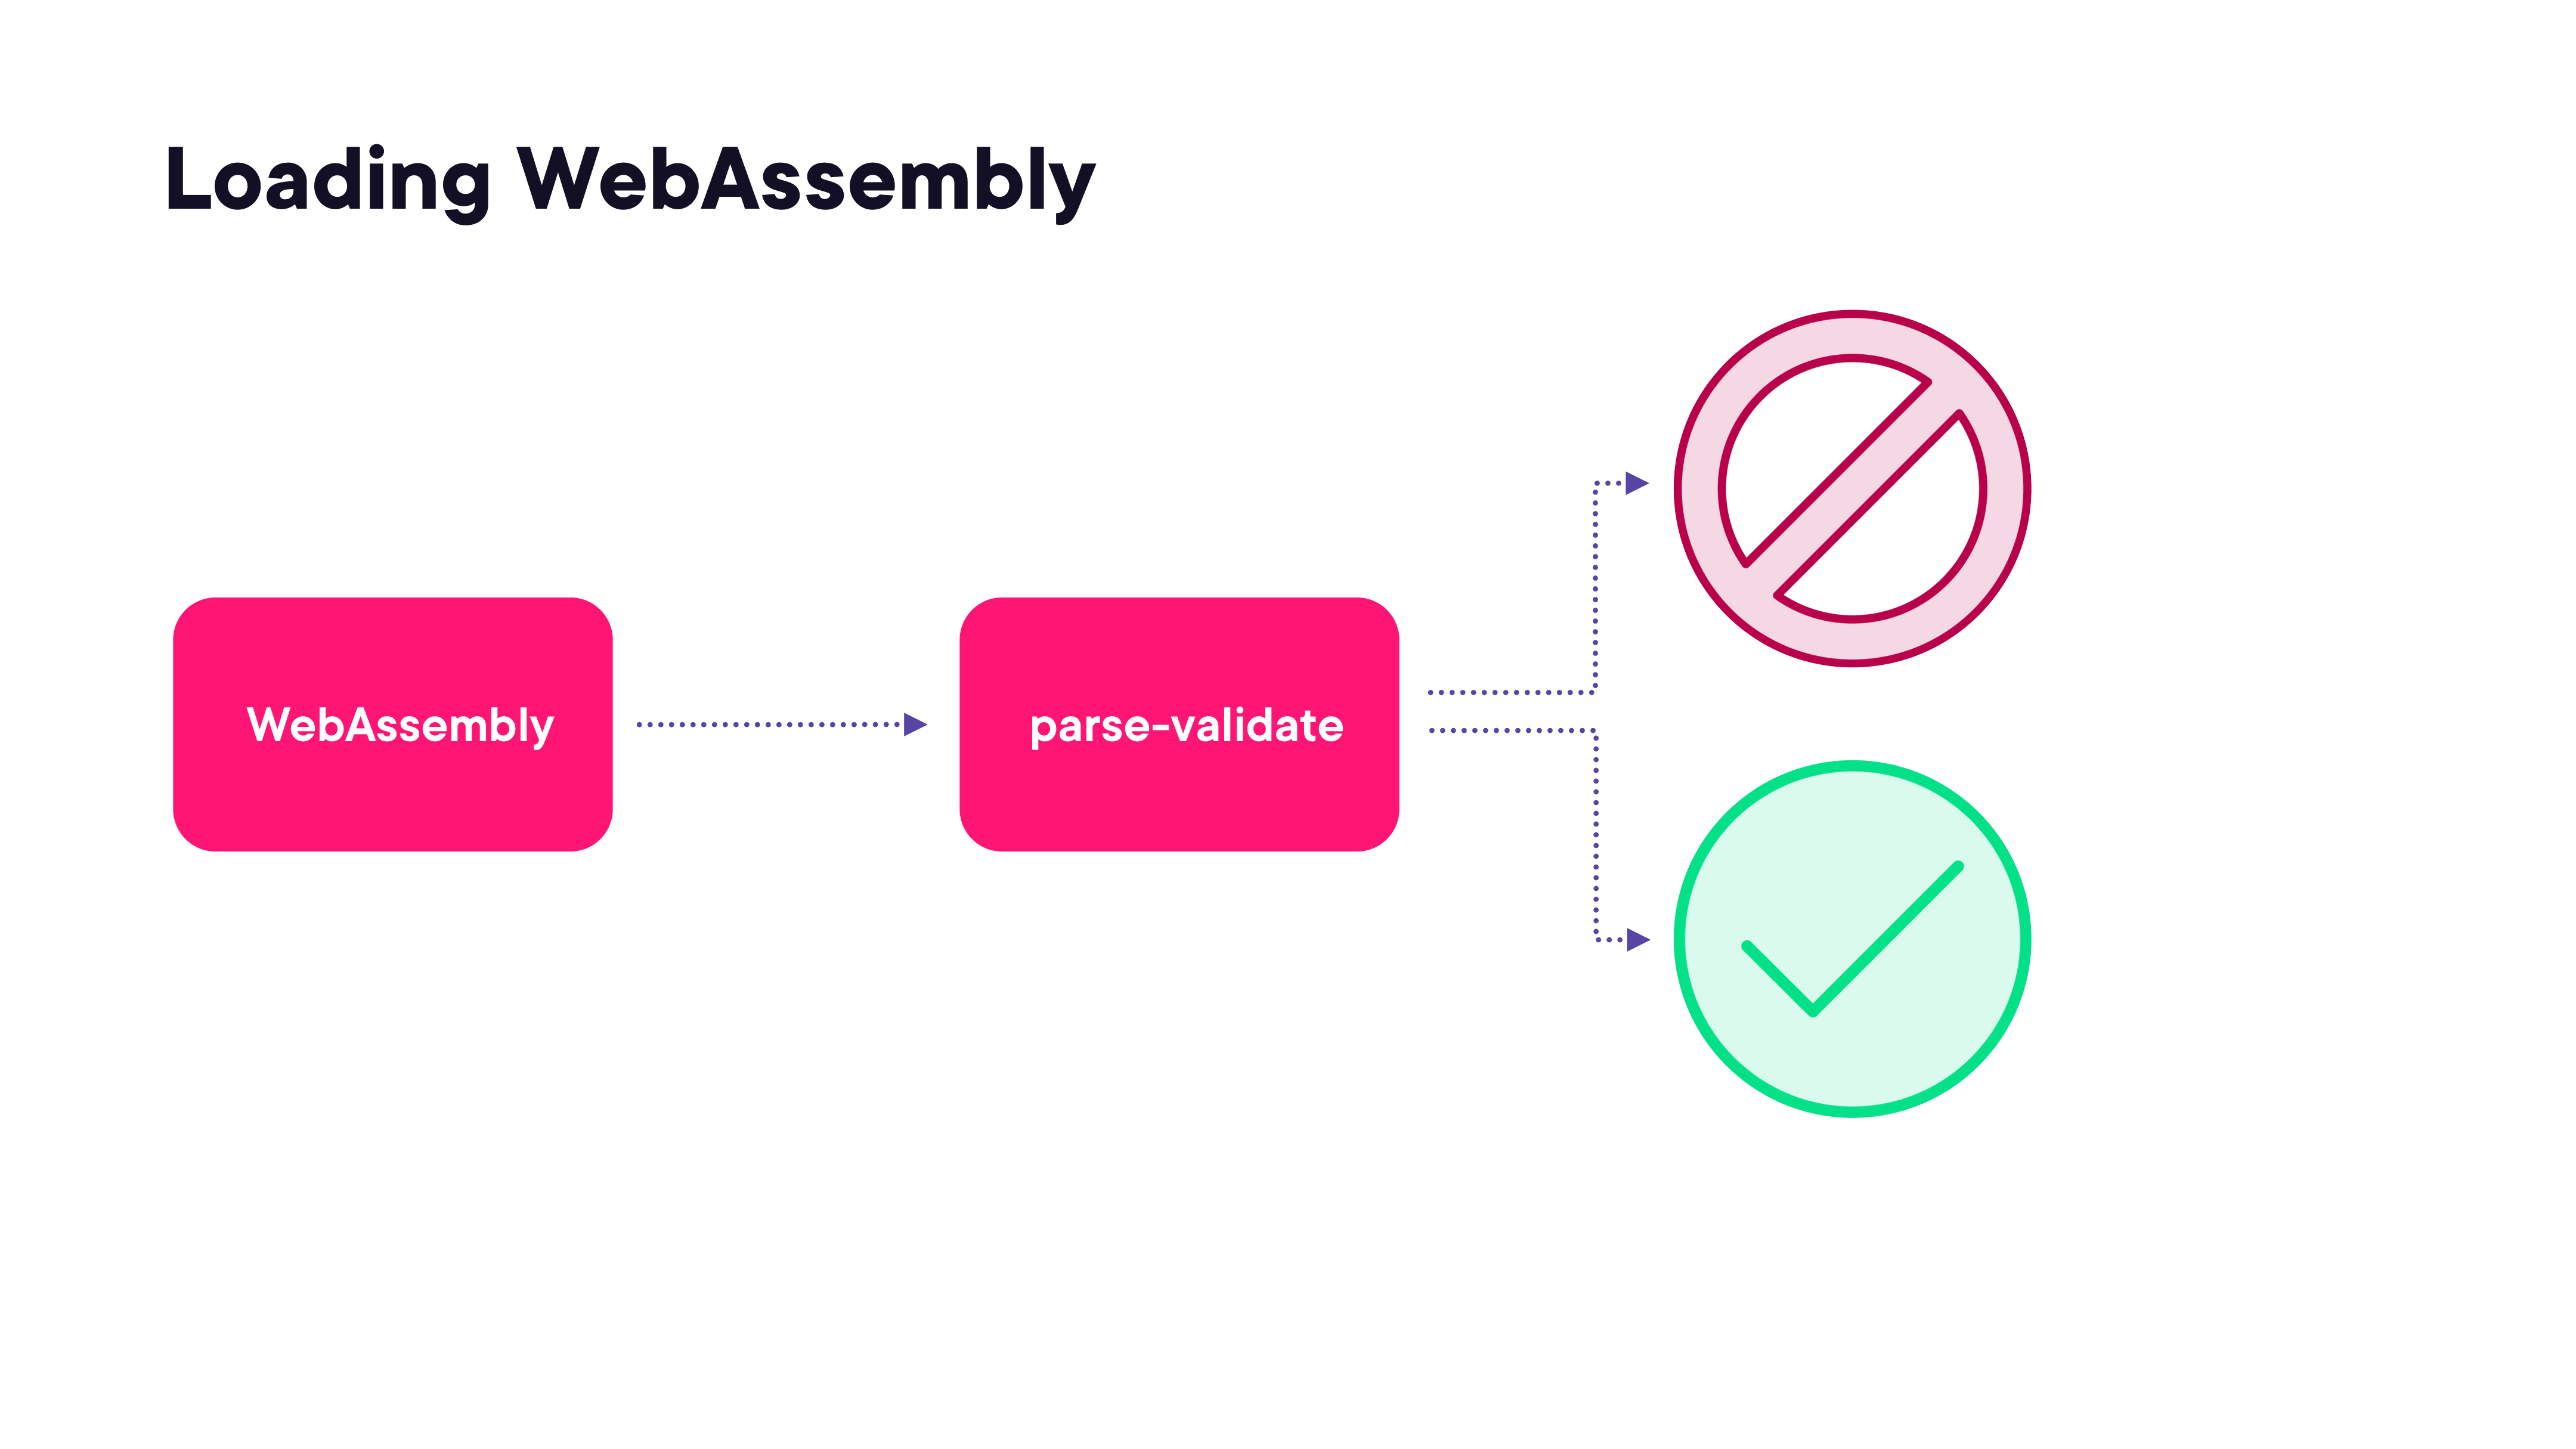

In [2]:
render_diagram(Path("assets/01-loading-webassembly-pipeline.png"))

When loading a WebAssembly module, the binary bytes first pass through a parse-validate step. If validation fails, a `WebAssembly.CompileError` is thrown. If validation succeeds, compilation proceeds to produce native machine code.


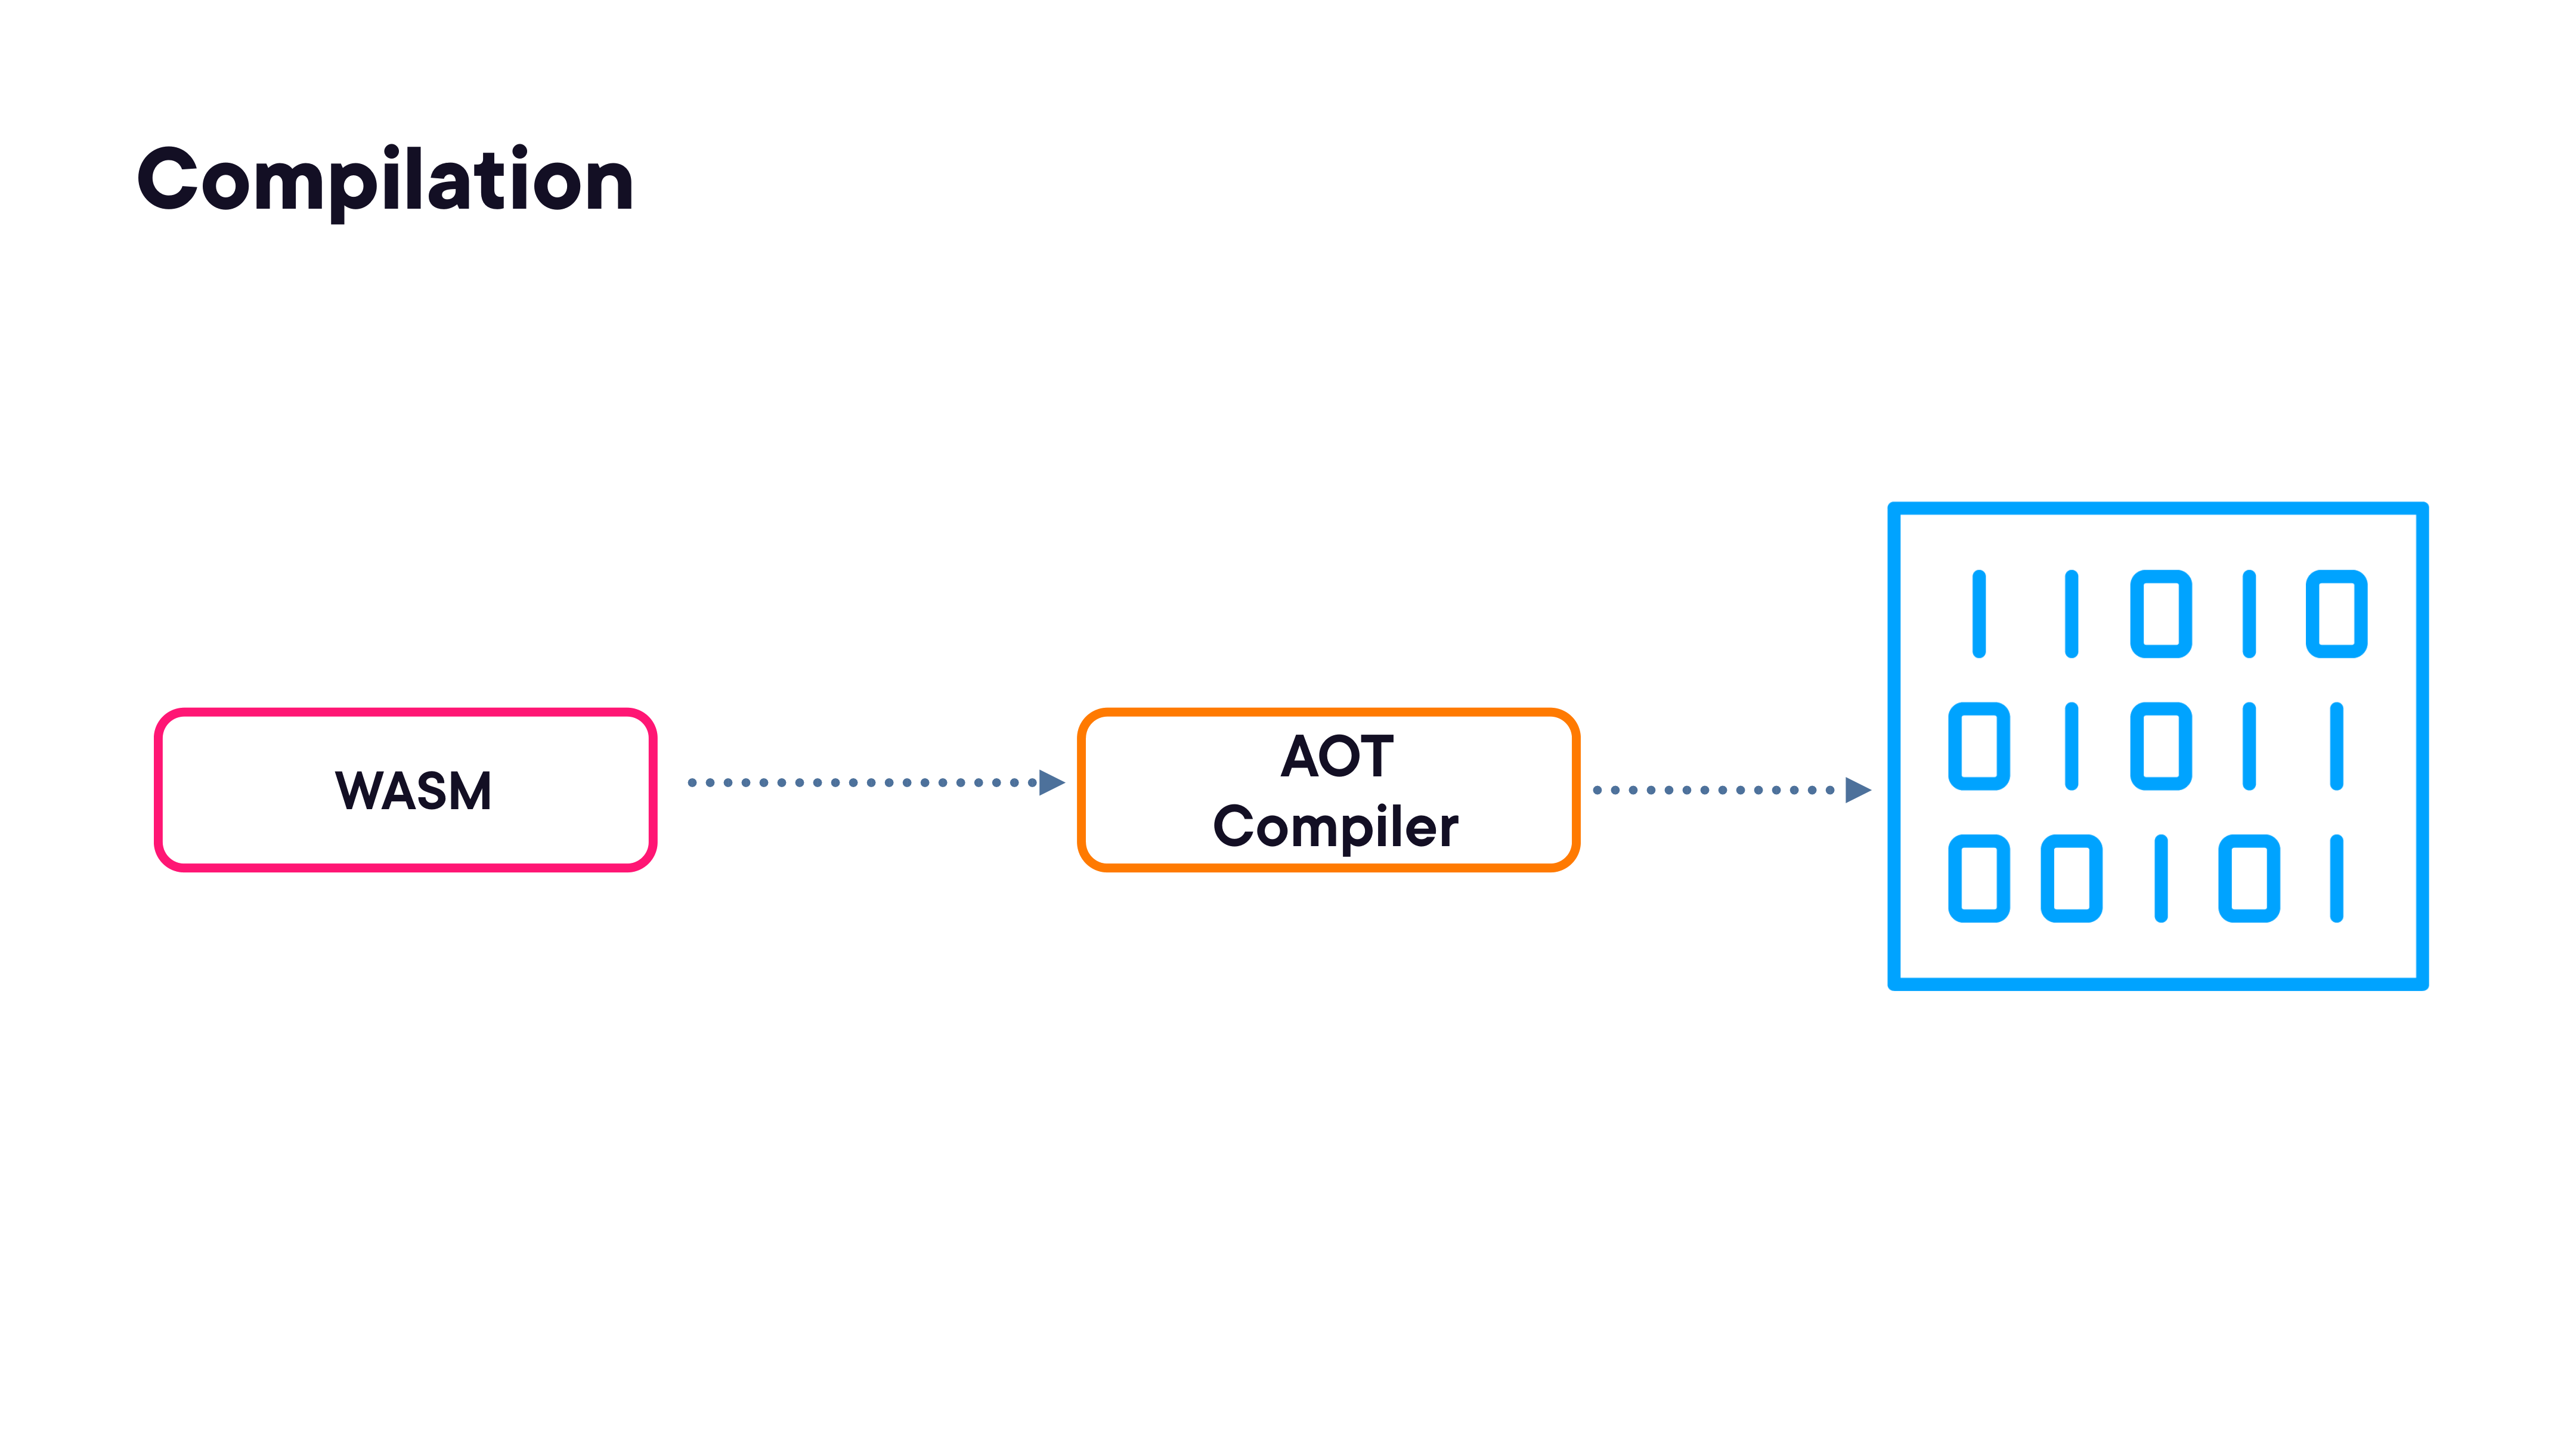

In [3]:
render_diagram(Path("assets/02-compilation-pipeline.png"))

WebAssembly bytecode is compiled by an ahead-of-time (AOT) compiler in the browser engine (V8, SpiderMonkey, JavaScriptCore) to native machine code. This is what makes Wasm execution near-native speed.

---

## Module 02: Loading Modules with the WebAssembly JavaScript API

The WebAssembly JavaScript API provides several methods for loading, compiling, and instantiating `.wasm` modules. This module covers each method, when to use it, and how the resulting objects are structured.

### The WebAssembly Namespace

All WebAssembly functionality is exposed through the global `WebAssembly` object. Its key members:

**Static methods:**
- `WebAssembly.instantiateStreaming()` — compile + instantiate from a streaming source (recommended)
- `WebAssembly.compileStreaming()` — compile only from a streaming source
- `WebAssembly.instantiate()` — compile + instantiate from a buffer or existing module
- `WebAssembly.compile()` — compile only from a buffer
- `WebAssembly.validate()` — check if bytes constitute a valid Wasm module

**Constructors:**
- `WebAssembly.Module` — compiled, stateless module
- `WebAssembly.Instance` — running instance with state
- `WebAssembly.Memory` — linear memory buffer
- `WebAssembly.Table` — function reference table
- `WebAssembly.Global` — a mutable or immutable global variable

**Error types:**
- `WebAssembly.CompileError` — invalid module binary
- `WebAssembly.LinkError` — import resolution failure
- `WebAssembly.RuntimeError` — trap during execution (e.g., divide by zero, OOB memory access)

### `WebAssembly.instantiateStreaming()` — The Recommended Approach

`instantiateStreaming` compiles and instantiates a WebAssembly module directly from a streaming network response. It is the most efficient loading method because compilation can begin before the entire `.wasm` file has been downloaded.

```javascript
const { instance, module } = await WebAssembly.instantiateStreaming(
  fetch('module.wasm'),
  importObject  // optional: supplies imports the Wasm module needs
);

// Access exported functions and values:
instance.exports.myFunction();
```

The returned object has two properties:
- `module` — the compiled `WebAssembly.Module` (can be cached or re-instantiated)
- `instance` — the running `WebAssembly.Instance`

**Requirement:** The server must serve the `.wasm` file with `Content-Type: application/wasm`. If not, use `WebAssembly.instantiate()` instead.

### `WebAssembly.compileStreaming()` — Separate Compile and Instantiate

Use `compileStreaming` when you want to compile a module once and then instantiate it multiple times (e.g., spawning multiple Web Workers each with their own instance of the same module).

```javascript
// Compile once (e.g., on startup or in a service worker)
const module = await WebAssembly.compileStreaming(fetch('module.wasm'));

// Later: instantiate multiple times from the cached module
const instance1 = await WebAssembly.instantiate(module, importObject);
const instance2 = await WebAssembly.instantiate(module, importObject);
```

`WebAssembly.Module` objects are transferable — they can be sent to Web Workers via `postMessage` without copying, enabling efficient module sharing across threads.

### `WebAssembly.instantiate()` — Buffer-Based Loading

When a streaming response is not available (e.g., the `Content-Type` header is wrong, or the module is loaded from a non-HTTP source), use `instantiate` with an `ArrayBuffer`:

```javascript
const response = await fetch('module.wasm');
const buffer = await response.arrayBuffer();
const { instance, module } = await WebAssembly.instantiate(buffer, importObject);
```

You can also pass a pre-compiled `WebAssembly.Module` directly:

```javascript
// From a cached / transferred module
const instance = await WebAssembly.instantiate(module, importObject);
```

When passed a buffer, `instantiate` returns both `module` and `instance`. When passed an existing module, it returns only an `instance`.

### `WebAssembly.validate()` — Check Before Compiling

`validate` synchronously checks whether a typed array or `ArrayBuffer` contains valid WebAssembly bytecode. Returns `true` or `false`.

```javascript
const response = await fetch('module.wasm');
const buffer = await response.arrayBuffer();

if (WebAssembly.validate(buffer)) {
  const { instance } = await WebAssembly.instantiate(buffer);
  // use instance
} else {
  console.error('Invalid WebAssembly module');
}
```

Useful for pre-flight validation before attempting compilation, or for defensive checks when receiving `.wasm` bytes from an untrusted source.

### The Import Object

Many Wasm modules require external values at instantiation time — functions, memory, tables, or globals that the module declares as imports. These are supplied via the **import object**:

```javascript
const importObject = {
  env: {
    // A JavaScript function callable from inside the Wasm module
    consoleLog: (value) => console.log(value),
    // Shared memory
    memory: new WebAssembly.Memory({ initial: 1 }),
  }
};

const { instance } = await WebAssembly.instantiateStreaming(
  fetch('module.wasm'),
  importObject
);
```

The import object is a two-level namespace: `{ moduleName: { itemName: value } }`. The names must exactly match the import declarations in the `.wasm` module.

If a required import is missing or has the wrong type, `WebAssembly.instantiate` will throw a `WebAssembly.LinkError`.

### Comparing Loading Methods

| Method | Input | Streaming | Returns |
|---|---|---|---|
| `instantiateStreaming()` | `Response` (fetch) | Yes | `{ module, instance }` |
| `compileStreaming()` | `Response` (fetch) | Yes | `Module` |
| `instantiate(buffer)` | `ArrayBuffer` | No | `{ module, instance }` |
| `instantiate(module)` | `Module` | No | `Instance` |
| `compile()` | `ArrayBuffer` | No | `Module` |
| `validate()` | `ArrayBuffer` | No | `boolean` (sync) |

Use streaming methods whenever possible — they allow the browser to begin compilation while bytes are still downloading, significantly reducing load time for large modules.

### Demo: Loading WebAssembly Modules

Hands-on examples covering each loading method in the WebAssembly JavaScript API.

See [`02-loading-modules-demos/`](02-loading-modules-demos/) for the full project.

- **`demo1-load-instance/`** — `instantiateStreaming` to load and call a Wasm module
- **`demo2-compile-module/`** — `compileStreaming` to separate compilation from instantiation
- **`demo3-result-object/`** — inspecting the result object (`module` + `instance` properties)
- **`demo4-validate/`** — `validate()` for pre-flight binary validation

Each demo has `before/` (starting point) and `after/` (completed solution) subdirectories. Serve the demos with a local HTTP server (`npx http-server` or `python3 -m http.server`) since `fetch` requires HTTP, not `file://`.

---

## Module 03: Functions

This module covers how WebAssembly functions are exported to JavaScript and imported from JavaScript, including how to use `WebAssembly.Table` for indirect function calls.

### Exporting Functions from WebAssembly

A Wasm module can export functions that JavaScript calls. The WAT `export` statement names the export and references an internal function:

```wat
(module
  (func $divide (param $numerator f64) (param $denominator f64) (result f64)
    local.get $numerator
    local.get $denominator
    f64.div
  )
  (export "divide" (func $divide))
)
```

On the JavaScript side, exported functions appear on `instance.exports`:

```javascript
const { instance } = await WebAssembly.instantiateStreaming(fetch('divide.wasm'));

const result = instance.exports.divide(10, 2);
console.log(result); // 5
```

Each exported function is a regular JavaScript function that can be called like any other. JavaScript numbers are automatically coerced to the Wasm parameter types.

### Importing Functions from JavaScript

A Wasm module can declare imports that must be satisfied by the JavaScript host at instantiation time. The WAT `import` statement specifies the two-level namespace (`module.name`) and the expected function signature:

```wat
(module
  (import "console" "log" (func $log (param f64)))

  (func $divide (param $n f64) (param $d f64) (result f64)
    local.get $n
    local.get $d
    f64.div
    call $log     ;; call imported JS function with result
    local.get $n
    local.get $d
    f64.div
  )
  (export "divide" (func $divide))
)
```

The corresponding import object in JavaScript:

```javascript
const importObject = {
  console: {
    log: (value) => console.log(value)
  }
};

const { instance } = await WebAssembly.instantiateStreaming(
  fetch('divide.wasm'),
  importObject
);
```

If the Wasm module calls an imported function, the call crosses back into JavaScript. This is sometimes called a **callback import** or **host function**.

### `WebAssembly.Table` — Indirect Function Calls

`WebAssembly.Table` is a resizable typed array of references — primarily used to hold function references for **indirect calls** (`call_indirect`). This is the mechanism used to implement function pointers from C/C++ in WebAssembly.

**Why indirect calls?** Direct calls in Wasm (`call $funcIndex`) require knowing the function at compile time. Indirect calls (`call_indirect`) look up the function in the table at runtime, enabling dynamic dispatch.

#### Creating a Table in WAT

```wat
(module
  (table 2 funcref)  ;; table with 2 slots
  (elem (i32.const 0) $add $subtract)  ;; populate slots 0 and 1

  (func $add (param i32 i32) (result i32)
    local.get 0
    local.get 1
    i32.add
  )
  (func $subtract (param i32 i32) (result i32)
    local.get 0
    local.get 1
    i32.sub
  )
  (type $binOp (func (param i32 i32) (result i32)))

  (func $callByIndex (param $opIndex i32) (param $a i32) (param $b i32) (result i32)
    local.get $a
    local.get $b
    local.get $opIndex
    call_indirect (type $binOp)  ;; call the function at table[$opIndex]
  )
  (export "callByIndex" (func $callByIndex))
)
```

#### Accessing the Table from JavaScript

```javascript
const { instance } = await WebAssembly.instantiateStreaming(fetch('table.wasm'));

// Call via table index: 0 = add, 1 = subtract
console.log(instance.exports.callByIndex(0, 10, 3));  // 13
console.log(instance.exports.callByIndex(1, 10, 3));  // 7
```

Tables can also be created in JavaScript and passed as imports, enabling JavaScript to populate the table with JS functions that the Wasm module calls indirectly.


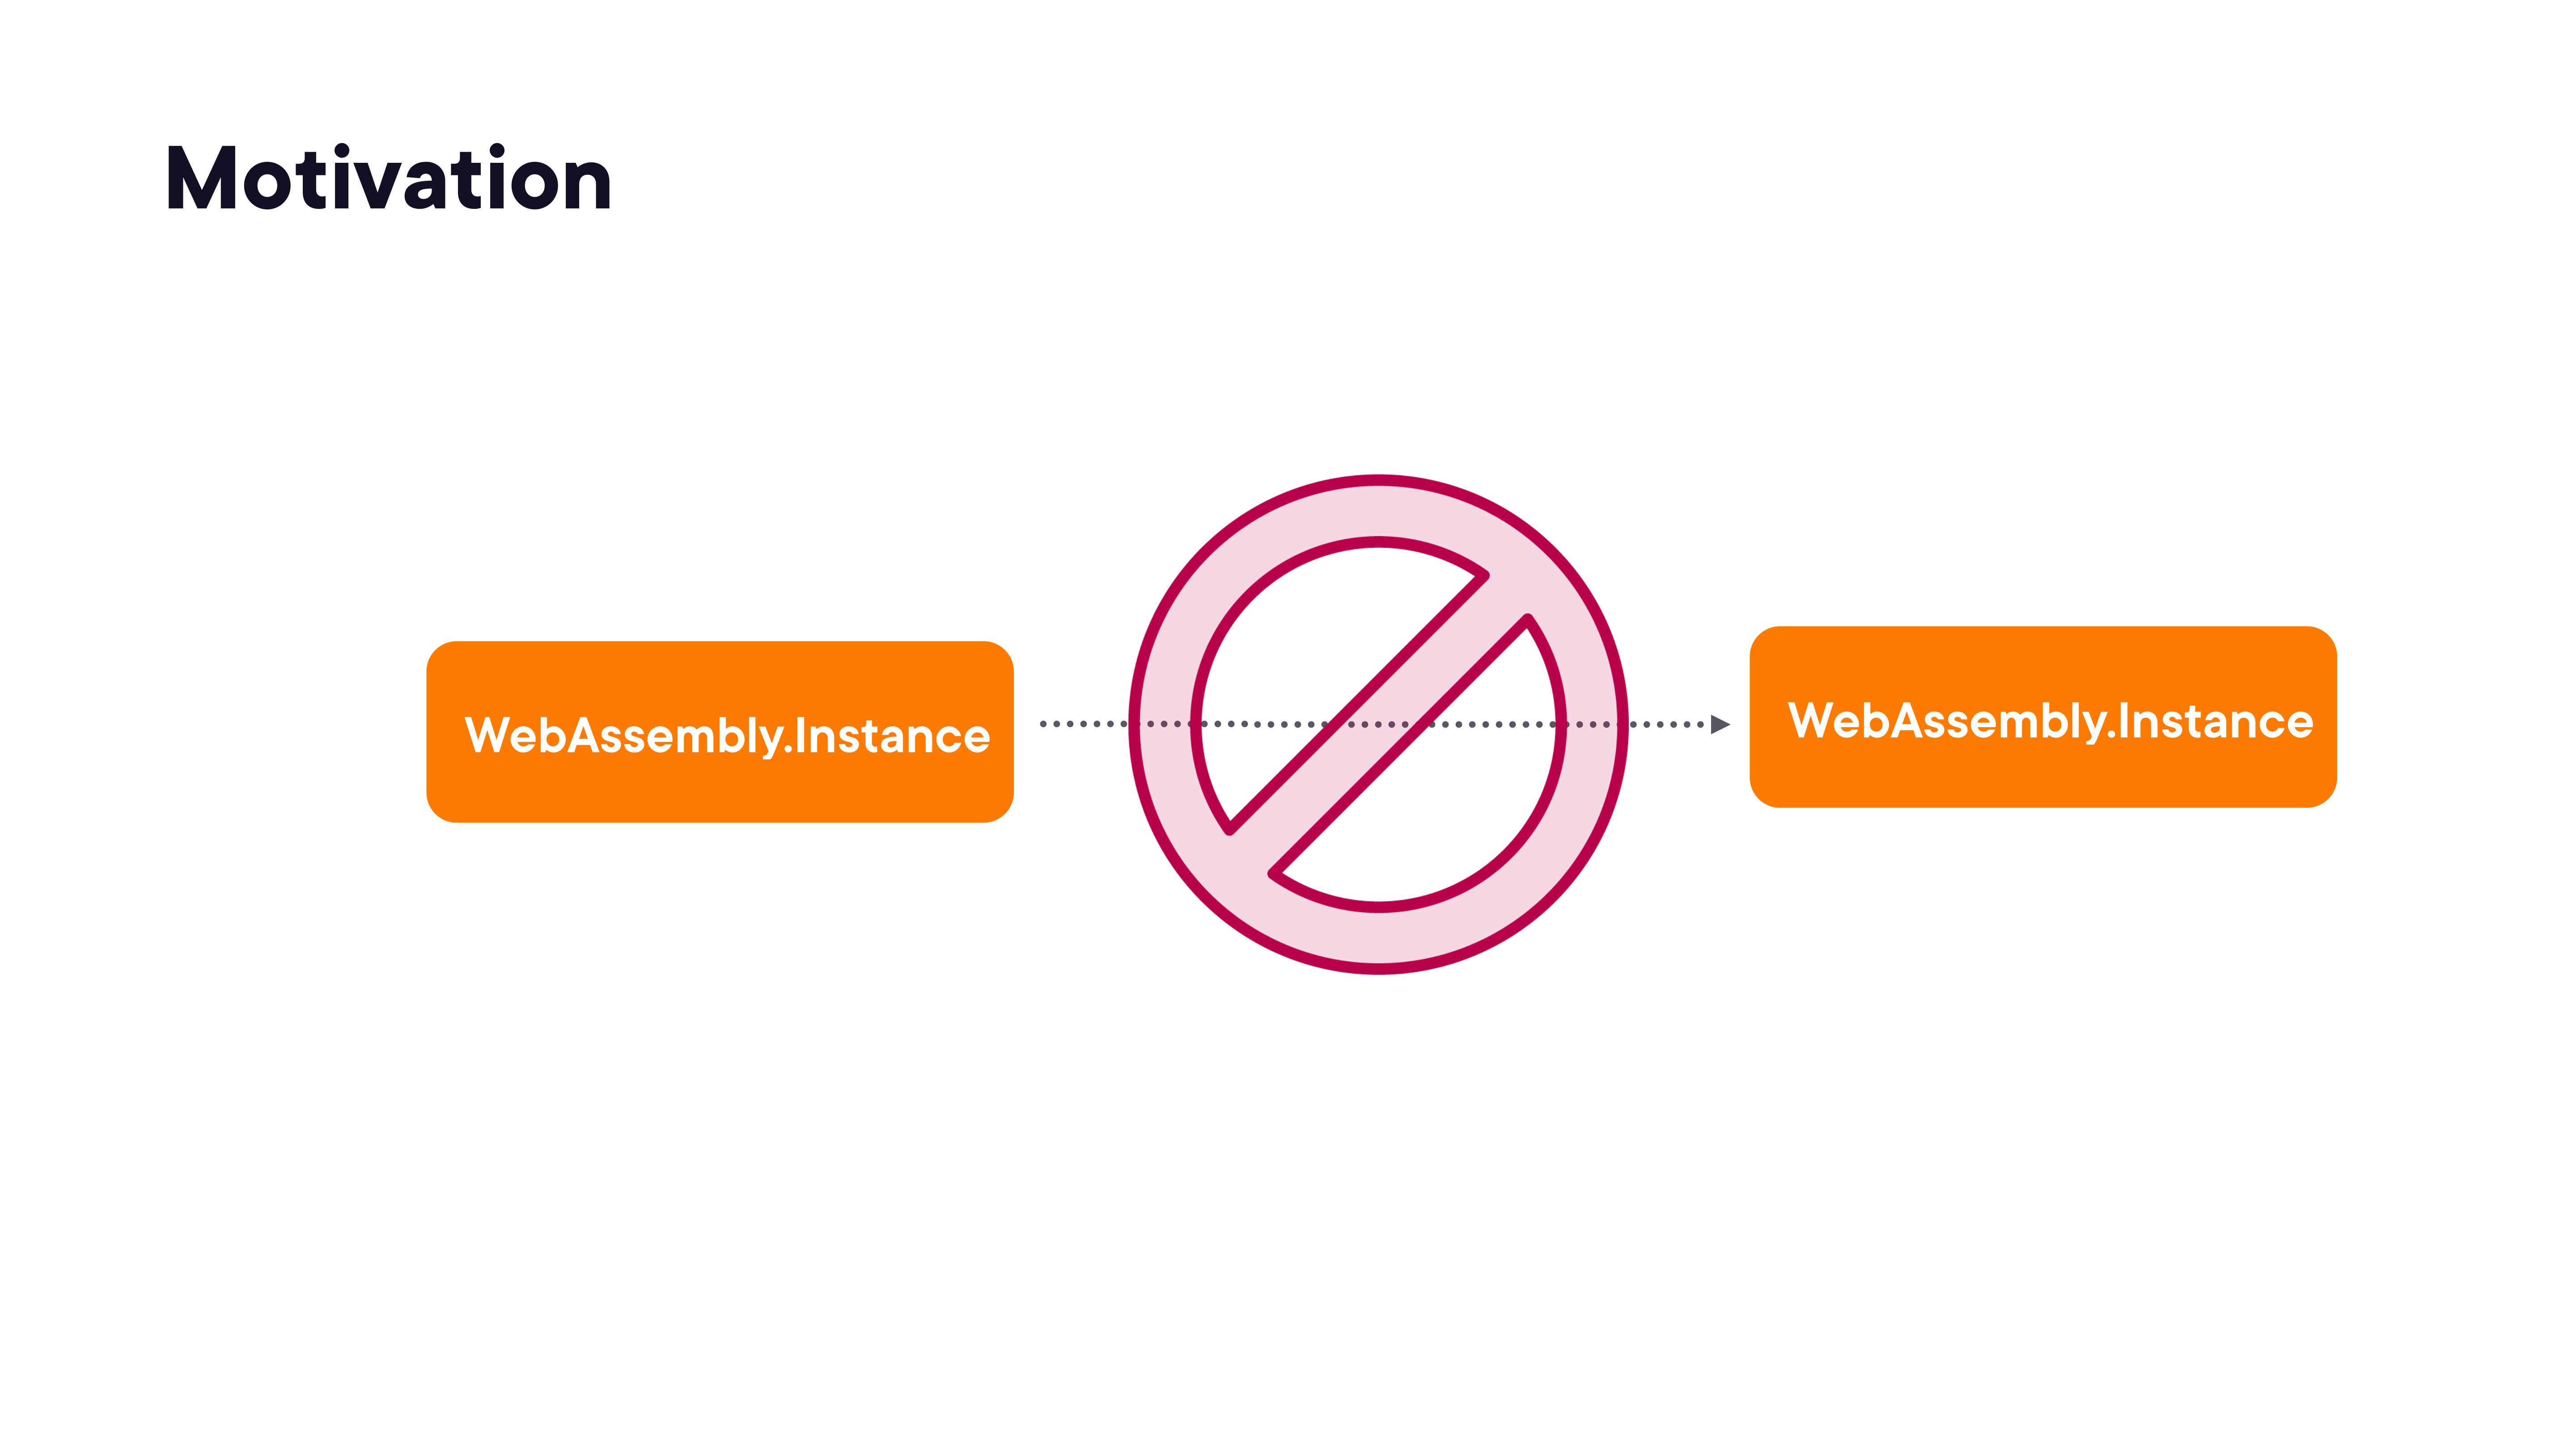

In [4]:
render_diagram(Path("assets/03-table-instance-isolation.png"))

Two `WebAssembly.Instance` objects cannot communicate directly with each other. `WebAssembly.Table` solves this — a shared table can be passed as an import to multiple instances, allowing them to indirectly call each other's functions.

### `WebAssembly.Table` API

A `WebAssembly.Table` can be created in JavaScript and passed as an import:

```javascript
const table = new WebAssembly.Table({
  initial: 2,    // initial number of slots
  element: 'anyfunc'  // function references
});

// Set entries
table.set(0, someJsFunction);
table.set(1, anotherJsFunction);

// Get a function from the table
const fn = table.get(0);
fn(arg1, arg2);

// Grow the table
table.grow(5);
console.log(table.length);  // 7
```

**`WebAssembly.Table` properties and methods:**

| Member | Description |
|---|---|
| `table.length` | Current number of accessible entries |
| `table.get(index)` | Returns the function reference at `index` |
| `table.set(index, fn)` | Sets the entry at `index` to function `fn` |
| `table.grow(n)` | Grows the table by `n` entries; returns old length |

### Demo: Functions — Exports, Imports, and Tables

Examples covering Wasm function exports, JavaScript function imports, and `WebAssembly.Table` for indirect calls.

See [`03-functions-demos/`](03-functions-demos/) for the full project.

- **`m4-demo1/`** — exporting functions from Wasm and calling them in JavaScript
- **`m4-demo2/`** — importing JavaScript functions into a Wasm module
- **`m4-demo3/`** — using `WebAssembly.Table` for indirect function dispatch (`call_indirect`)

---

## Module 04: Globals and Memory

This module covers `WebAssembly.Global` for sharing scalar values between JavaScript and WebAssembly, and `WebAssembly.Memory` for sharing bulk data through linear memory.

### `WebAssembly.Global` — Shared Scalar Values

`WebAssembly.Global` represents a single typed scalar value that can be shared between JavaScript and one or more WebAssembly instances. Globals can be mutable or immutable.

#### Creating a Global in JavaScript

```javascript
const myGlobal = new WebAssembly.Global(
  { value: 'f64', mutable: true },
  3.14  // initial value
);

console.log(myGlobal.value);  // 3.14
myGlobal.value = 2.72;         // set a new value (only if mutable)
```

Supported value types: `'i32'`, `'i64'`, `'f32'`, `'f64'`.

#### Passing a Global as an Import

```javascript
const g = new WebAssembly.Global({ value: 'f64', mutable: true }, 0);

const importObject = {
  js: { global: g }
};

const { instance } = await WebAssembly.instantiateStreaming(
  fetch('module.wasm'), importObject
);

// Both JS and Wasm share the same value
instance.exports.increment();
console.log(g.value);  // updated by Wasm
```

#### Declaring a Global in WAT

```wat
(module
  (import "js" "global" (global $g (mut f64)))

  (func $increment
    global.get $g
    f64.const 1
    f64.add
    global.set $g
  )
  (export "increment" (func $increment))
)
```

Globals are useful for passing configuration values into Wasm modules or for sharing counters and state flags without the overhead of memory reads.

### `WebAssembly.Memory` — Linear Memory

`WebAssembly.Memory` is a resizable `ArrayBuffer` that serves as the **linear memory** of a WebAssembly instance. Both JavaScript and the Wasm module read and write to the same underlying buffer.

Linear memory is measured in **pages**, where each page is **64 KiB** (65,536 bytes).

#### Creating Memory in JavaScript

```javascript
const memory = new WebAssembly.Memory({
  initial: 1,   // 1 page = 64 KiB
  maximum: 10   // can grow up to 10 pages (optional)
});

// memory.buffer is an ArrayBuffer
const view = new Int32Array(memory.buffer);
view[0] = 42;

// Grow memory
memory.grow(1);  // grow by 1 more page
console.log(memory.buffer.byteLength);  // 131072 (2 pages)
```

> **Important:** After calling `memory.grow()`, the old `memory.buffer` reference becomes detached (its `byteLength` becomes 0). Always re-read `memory.buffer` after a grow.

#### Sharing Memory as an Import

```javascript
const memory = new WebAssembly.Memory({ initial: 1 });
const importObject = { env: { memory } };

const { instance } = await WebAssembly.instantiateStreaming(
  fetch('module.wasm'), importObject
);

// Write data into shared memory for Wasm to read
const bytes = new Uint8Array(memory.buffer);
bytes[0] = 72;  // 'H'
bytes[1] = 105; // 'i'
```

### Reading Strings from Linear Memory

WebAssembly has no string type. Strings are stored as bytes in linear memory. To pass a string from Wasm to JavaScript, the Wasm module writes the bytes to memory and returns a pointer (offset) and length. JavaScript then reads the bytes and decodes them:

```javascript
const { instance } = await WebAssembly.instantiateStreaming(fetch('strings.wasm'));
const memory = instance.exports.memory;

// Wasm returns a pointer to a string in memory
const ptr = instance.exports.getString();

// Read bytes until null terminator (C-style) or use a returned length
const bytes = new Uint8Array(memory.buffer, ptr);
let len = 0;
while (bytes[len] !== 0) len++;

const str = new TextDecoder().decode(new Uint8Array(memory.buffer, ptr, len));
console.log(str);
```

For performance-sensitive code, reuse the `TextDecoder` instance rather than creating it on each call.

### Shared Memory and Atomics

`WebAssembly.Memory` can be made **shared** for use across multiple Web Workers (threads):

```javascript
const sharedMemory = new WebAssembly.Memory({
  initial: 1,
  maximum: 10,
  shared: true   // enables SharedArrayBuffer semantics
});
```

A shared memory's `buffer` property is a `SharedArrayBuffer` instead of a regular `ArrayBuffer`. This enables true parallel execution — multiple workers can read and write to the same memory concurrently.

Use `Atomics` operations for safe concurrent access:

```javascript
const i32 = new Int32Array(sharedMemory.buffer);

// Atomic read/write
Atomics.store(i32, 0, 42);
const val = Atomics.load(i32, 0);

// Atomic compare-and-swap (lock-free synchronization)
Atomics.compareExchange(i32, 0, expected, replacement);

// Wait/notify (mutex-like)
Atomics.wait(i32, 0, 0);   // block until i32[0] != 0
Atomics.notify(i32, 0, 1); // wake 1 waiting thread
```

**Requirements for shared memory:**
- The page must be served with `Cross-Origin-Opener-Policy: same-origin` and `Cross-Origin-Embedder-Policy: require-corp` headers (COOP/COEP)
- These headers re-enable `SharedArrayBuffer` which was restricted after Spectre

### Demo: Globals and Memory

Examples demonstrating `WebAssembly.Global` for shared scalars and `WebAssembly.Memory` for linear memory, including a C quicksort implementation that processes data via shared memory.

See [`04-globals-memory-demos/`](04-globals-memory-demos/) for the full project.

- **`m5-demo1/`** — creating and sharing `WebAssembly.Global` values between JS and Wasm
- **`m5-demo2/`** — using `WebAssembly.Memory` to share data; includes a C quicksort that sorts a large employee dataset (`employees.json`) via Wasm memory
- **`m5-demo3/`** — memory with a Node.js/Express server setup

---

## Module 05: Exception Handling and Debugging

WebAssembly errors divide into compile-time, link-time, and runtime categories. This module also covers the newer fine-grained exception handling API and debugging approaches.

### Error Types

Three error types can be thrown during the WebAssembly lifecycle:

| Error | When thrown | Cause |
|---|---|---|
| `WebAssembly.CompileError` | At compile time | The `.wasm` binary is malformed or contains invalid bytecode |
| `WebAssembly.LinkError` | At instantiation time | An import declared by the module is missing or has the wrong type |
| `WebAssembly.RuntimeError` | At execution time | A trap condition is triggered (divide by zero, OOB memory, unreachable, type mismatch in indirect call) |

All three inherit from `Error` and have `name`, `message`, and `stack` properties.

```javascript
try {
  const { instance } = await WebAssembly.instantiateStreaming(
    fetch('module.wasm'),
    importObject
  );
} catch (e) {
  if (e instanceof WebAssembly.CompileError) {
    console.error('Module binary is invalid:', e.message);
  } else if (e instanceof WebAssembly.LinkError) {
    console.error('Import mismatch:', e.message);
  } else if (e instanceof WebAssembly.RuntimeError) {
    console.error('Trap during execution:', e.message);
  }
}
```

### Runtime Traps

A **trap** is a fatal error that halts execution of the WebAssembly module. When a trap occurs, it propagates to the calling JavaScript as a `WebAssembly.RuntimeError`.

Common trap conditions:

- **Divide by zero** — integer division or remainder with a zero divisor (`i32.div_s`, `i32.rem_s`, etc.)
- **Out-of-bounds memory access** — reading or writing outside the bounds of linear memory
- **Out-of-bounds table access** — `call_indirect` with an index outside the table bounds
- **Null reference** — calling through a null function reference
- **Unreachable** — execution reached an explicit `unreachable` instruction
- **Stack overflow** — too many nested calls
- **Type mismatch in `call_indirect`** — the actual function type doesn't match the declared type

```javascript
try {
  instance.exports.divideByZero();
} catch (e) {
  // WebAssembly.RuntimeError: divide by zero
  console.error(e.message);
}
```

### Fine-Grained Exception Handling — `WebAssembly.Tag` and `WebAssembly.Exception`

The **WebAssembly Exception Handling** proposal (Phase 4) adds structured exceptions similar to `try/catch/throw` in high-level languages. This is the mechanism used by Emscripten to propagate C++ exceptions through WebAssembly.

#### `WebAssembly.Tag`

A `Tag` defines an exception type by its value types (payload types):

```javascript
const tag = new WebAssembly.Tag({ parameters: ['i32', 'f64'] });
```

Tags are used as type identifiers. The same `Tag` object that was used to throw an exception must be available to catch it.

#### Throwing and Catching Wasm Exceptions in JavaScript

When a WebAssembly module throws a tagged exception, it propagates to JavaScript as a `WebAssembly.Exception` object. Use `exception.is(tag)` to test its type and `exception.getArg(tag, index)` to extract its payload:

```javascript
const tag = new WebAssembly.Tag({ parameters: ['i32'] });
const importObject = { env: { tag } };

const { instance } = await WebAssembly.instantiateStreaming(
  fetch('module.wasm'), importObject
);

try {
  instance.exports.throwException();
} catch (e) {
  if (e instanceof WebAssembly.Exception && e.is(tag)) {
    const code = e.getArg(tag, 0);
    console.log('Wasm threw with code:', code);
  } else {
    throw e;  // re-throw if it's not ours
  }
}
```

#### Throwing from JavaScript into Wasm

You can also create a `WebAssembly.Exception` in JavaScript and throw it into Wasm code that uses `catch`:

```javascript
const ex = new WebAssembly.Exception(tag, [42]);
throw ex;
```

### Debugging WebAssembly

Debugging Wasm is more complex than debugging JavaScript, but several tools and techniques are available:

**Browser DevTools:**
- Chrome and Firefox DevTools can step through `.wat` source maps if the `.wasm` was built with DWARF debug info
- The "Sources" panel shows disassembled WAT alongside the binary
- Breakpoints can be set inside Wasm functions

**Source Maps:**
- Emscripten can emit DWARF debug info embedded in `.wasm` or as a separate `.wasm.map` file
- With DWARF info, DevTools shows the original C/C++ source

**Practical Debugging Approaches:**
- Use imported JS functions as debug probes (print values from within Wasm)
- `wasm2wat` to decompile and inspect the binary
- Use `WebAssembly.validate()` to confirm the module is well-formed before instantiation
- Check `instance.exports` in the console to confirm what was actually exported
- Use `try/catch` around all instantiation and function calls to capture error messages

```javascript
// Debug probe: import a print function
const importObject = {
  debug: {
    print: (val) => console.log('[wasm]', val)
  }
};
```

### Demo: Exception Handling and Debugging

Examples covering `WebAssembly.CompileError`, `LinkError`, `RuntimeError`, tagged exceptions with `WebAssembly.Tag`, and DevTools debugging.

See [`05-exception-handling-demos/`](05-exception-handling-demos/) for the full project.

- **`m6-demo1/`** — triggering and catching `CompileError`, `LinkError`, and `TypeError`
- **`m6-demo2/`** — integer divide-by-zero trap, `WebAssembly.Tag`, and typed exceptions
- **`m6-demo3/`** — debugging a divide trap in Chrome/Firefox DevTools with `.wat` source

---

## Module 06: Runtimes

WebAssembly is no longer browser-only. This module covers running Wasm in Node.js, the WebAssembly System Interface (WASI), and standalone runtimes like Wasmtime.

### WebAssembly in Node.js

Node.js has native support for WebAssembly using the same `WebAssembly` global API as browsers. The key difference is how `.wasm` files are loaded — instead of `fetch`, use `fs.readFile` or `fs.promises.readFile`:

```javascript
import { readFile } from 'fs/promises';
import { WebAssembly } from 'wasm'; // standard global in Node

// Load and instantiate
const buffer = await readFile('./module.wasm');
const { instance } = await WebAssembly.instantiate(buffer);

console.log(instance.exports.add(3, 4)); // 7
```

Node.js also supports streaming instantiation when loading from an HTTP endpoint using `node-fetch` or the native `fetch` (Node 18+):

```javascript
const { instance } = await WebAssembly.instantiateStreaming(
  fetch('https://example.com/module.wasm')
);
```

**Key difference from browsers:** Node.js modules that interact with the file system, network, or OS must use the WASI API or explicit import objects — Wasm code itself has no access to system resources by default.

### WASI — WebAssembly System Interface

WASI is a standard interface that gives WebAssembly programs controlled access to system resources: files, environment variables, command-line arguments, clocks, and random numbers. It is designed for running Wasm **outside browsers** on servers, edge nodes, and embedded systems.

WASI is **capability-based** — a Wasm module only gets access to the specific resources explicitly granted by the host, not implicit access to the entire file system or network.

#### Using WASI in Node.js

Node.js includes a built-in `WASI` class:

```javascript
import { WASI } from 'wasi';
import { readFile } from 'fs/promises';

const wasi = new WASI({
  version: 'preview1',
  args: process.argv,
  env: process.env,
  preopens: {
    '/sandbox': '/path/to/allowed/directory'  // grant FS access
  }
});

const buffer = await readFile('./module.wasm');
const { instance } = await WebAssembly.instantiate(buffer, {
  wasi_snapshot_preview1: wasi.wasiImport  // the WASI import object
});

wasi.start(instance);  // calls _start() (the entry point)
```

WASI versions:
- **`wasi_snapshot_preview1`** — the most widely implemented version (current standard)
- **`preview2`** — next generation (component model), not yet universally supported

### Wasmtime — Standalone WebAssembly Runtime

**Wasmtime** is a standalone, production-ready WebAssembly runtime built by the Bytecode Alliance. It runs `.wasm` files outside of a browser or Node.js, and supports WASI.

**Key properties:**
- Fast startup time, designed for serverless and edge use cases
- Full WASI support
- Security-hardened sandbox
- Available as a CLI and as an embeddable library

**Language bindings available for:**

| Language | Package |
|---|---|
| Rust | `wasmtime` crate |
| C/C++ | `libwasmtime` |
| Python | `wasmtime-py` |
| .NET | `Wasmtime` NuGet |
| Go | `wasmtime-go` |
| Ruby | `wasmtime-rb` |
| Bash (CLI) | `wasmtime` binary |

#### Running from the CLI

```bash
# Install
curl https://wasmtime.dev/install.sh -sSf | bash

# Run a WASI module
wasmtime module.wasm

# Pass arguments
wasmtime module.wasm -- arg1 arg2

# Grant file system access
wasmtime --dir /path/to/sandbox module.wasm
```

#### Embedding Wasmtime in .NET

```csharp
using Wasmtime;

var engine = new Engine();
var module = Module.FromFile(engine, "module.wasm");

using var linker = new Linker(engine);
using var store = new Store(engine);

linker.DefineWasi();
store.SetWasiConfiguration(new WasiConfiguration());

var instance = linker.Instantiate(store, module);
var run = instance.GetFunction(store, "run");
run?.Invoke(store);
```

### Demo: Runtimes

Examples running WebAssembly in Node.js, with WASI, and with Wasmtime (including a .NET embedding).

See [`06-runtimes-demos/`](06-runtimes-demos/) for the full project.

- **`demo1/`** — loading and running a Wasm module in Node.js using `fs.readFile` and `WebAssembly.instantiate`
- **`demo2/`** — WASI with Node.js `WASI` class: granting file system access via `preopens`
- **`demo3/dot-net/`** — Wasmtime embedded in a .NET application; `demo3/wasmtime/` — Wasmtime CLI usage

---

## Module 07: Tools and Languages

Three major toolchains bring existing and new code to WebAssembly: Emscripten (C/C++), Rust with wasm-bindgen/wasm-pack, and Blazor (.NET/C#).

### Emscripten — C/C++ to WebAssembly

**Emscripten** is the most widely-used toolchain for compiling C and C++ to WebAssembly. It uses LLVM as its compiler backend and targets WebAssembly as an output format.

**What Emscripten generates:**
- A `.wasm` binary
- A JavaScript "glue" file (`.js`) that loads and wires the `.wasm`
- Optionally an HTML shell file for browser testing

**Features:**
- Compiles the C standard library to Wasm (no OS needed)
- Emulates POSIX APIs (file system, sockets) in the browser via JavaScript
- Supports C++ exceptions via the WebAssembly exception handling proposal
- Can compile existing C/C++ projects with minimal source changes

#### Basic Usage

```bash
# Compile a C file to Wasm + JS glue
emcc hello_world.c -o hello_world.js

# Compile with exports
emcc hello_world.c \
  -o hello_world.js \
  -s EXPORTED_FUNCTIONS='["_add", "_subtract"]' \
  -s EXPORTED_RUNTIME_METHODS='["ccall", "cwrap"]'
```

The leading underscore in exported names (`_add`) is a C convention for Emscripten exports. When calling from JavaScript via `ccall`/`cwrap`, omit the underscore:

```javascript
// Using cwrap to create a callable JS wrapper
const add = Module.cwrap('add', 'number', ['number', 'number']);
console.log(add(3, 7)); // 10

// Using ccall for one-off calls
const result = Module.ccall('add', 'number', ['number', 'number'], [3, 7]);
```

### Emscripten: Importing JavaScript into C

Emscripten can also call JavaScript functions from C code using `EM_JS` and `EM_ASM` macros:

```c
#include <emscripten.h>

// EM_JS: define a JS function callable from C
EM_JS(void, alert_js, (const char* str), {
    alert(UTF8ToString(str));
});

// EM_ASM: inline JS code in a C function
void run_inline_js() {
    EM_ASM(
        console.log('Hello from inline JavaScript');
    );
}

int main() {
    alert_js("Hello from C!");
    run_inline_js();
    return 0;
}
```

`UTF8ToString` is an Emscripten runtime helper that converts a C string pointer to a JavaScript string.

### Rust and WebAssembly

Rust has first-class WebAssembly support and is quickly becoming one of the most popular languages for writing new Wasm modules from scratch.

**Why Rust for Wasm?**
- No runtime or garbage collector — compiles to lean, minimal Wasm binaries
- Memory safety without a GC
- Strong ecosystem with dedicated Wasm tooling
- Generates clean packages for easy deployment

**Key tools:**
- `wasm-bindgen` — generates JavaScript/TypeScript bindings for Rust-exported functions
- `wasm-pack` — builds, tests, and packages Rust-generated Wasm for npm

#### Writing a Rust Function for Wasm

```rust
// src/lib.rs
use wasm_bindgen::prelude::*;

#[wasm_bindgen]
extern {
    fn alert(s: &str);  // import from JavaScript
}

#[wasm_bindgen]
pub fn divide(numerator: usize, denominator: usize) -> usize {
    numerator / denominator
}
```

The `#[wasm_bindgen]` attribute on an `extern` block marks functions to import from JavaScript. On `pub fn`, it marks functions to export to JavaScript.

#### Building with wasm-pack

```bash
wasm-pack build --target web
```

This generates a `pkg/` directory containing:
- `module.wasm` — the compiled Wasm binary
- `module.js` — JavaScript bindings (auto-generated)
- `module.d.ts` — TypeScript declarations (auto-generated)
- `package.json` — npm package manifest

#### Using the Generated Package in HTML

```html
<script type="module">
  import init, { divide } from "./pkg/divide_rust.js";

  init().then(() => {
    console.log(`10 / 2 = ${divide(10, 2)}`);
  });
</script>
```

`init()` loads and instantiates the `.wasm` file. After it resolves, all exported functions are available directly by name.

### Blazor — C# and .NET to WebAssembly

**Blazor** is Microsoft's framework for building web applications using C# and .NET instead of JavaScript. It runs .NET on WebAssembly in the browser.

**How Blazor WebAssembly works:**
- Uses Emscripten to compile the .NET runtime (mono/CoreCLR) to WebAssembly
- Your C# application code is **not** compiled directly to Wasm — it is compiled to .NET IL (intermediate language), which the .NET runtime (itself in Wasm) interprets/JITs
- Blazor automatically generates the JavaScript interop layer

**Characteristics:**

- **Framework** — for building complete web applications (not just isolated functions)
- **Large initial download** — .NET runtime in Wasm is substantial (~2 MB compressed)
- **Lazy loading** — supports lazy-loading assemblies to reduce initial payload
- **AOT compilation** — optional ahead-of-time compilation of IL to Wasm for better runtime performance

#### JavaScript Interop in Blazor

Blazor provides `IJSRuntime` for calling JavaScript from C#:

```csharp
@inject IJSRuntime JS

// Call a JavaScript function from C#
await JS.InvokeVoidAsync("console.log", "Hello from Blazor!");
var result = await JS.InvokeAsync<int>("Math.max", 3, 7);
```

And `[JSInvokable]` for calling C# from JavaScript:

```csharp
[JSInvokable]
public static string GetGreeting(string name) => $"Hello, {name}!";
```

```javascript
// Call C# from JavaScript
const greeting = await DotNet.invokeMethodAsync('MyAssembly', 'GetGreeting', 'World');
```

### Choosing a Toolchain

| Toolchain | Language | Best for |
|---|---|---|
| Emscripten | C/C++ | Porting existing C/C++ libraries and applications to the web |
| Rust + wasm-pack | Rust | Writing new, high-performance Wasm modules from scratch |
| Blazor | C# / .NET | Full web applications when the team already has .NET expertise |

**Summary:**
- **Emscripten** is the most ubiquitous tool for creating WebAssembly applications from existing C/C++ code
- **Rust** is quickly becoming a common language for building new WebAssembly modules from scratch — minimal binary size and no GC
- **Blazor** is an easy way to create WebAssembly-based web applications using C# and .NET, but not a WebAssembly-first tool

### Demo: Tools and Languages

Examples using Emscripten (C to Wasm), Rust + wasm-pack (Rust to Wasm), and a Blazor WebAssembly project.

See [`07-tools-languages-demos/`](07-tools-languages-demos/) for the full project.

- **`demo1/`** — Emscripten: `hello_world.c` compiled to Wasm with `emcc`; `import-export.c` demonstrates `EM_JS`/`EM_ASM` macros for JS interop
- **`demo2/divide-rust/`** — Rust `divide` function built with `wasm-pack`; `pkg/` contains the generated JS bindings and `.wasm` output; `src/lib.rs` shows the `#[wasm_bindgen]` annotations
- **`demo3/`** — Blazor WebAssembly application demonstrating C#/JavaScript interop